---
title: "Topic-Level Sentiment Analysis of Shopee App User Reviews on Google Play"
description: " "
date: 2024-05-20
categories: [Large Language Model, Natural Language Processing, Sentiment Analysis, Topic Detection]
image: images/shopee.jpg
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../index.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">Topic-Level Sentiment Analysis of Shopee App User Reviews on Google Play</li>
</ol>

## Overview

This project analyzes user reviews of the Shopee application on Google Play by combining sentiment classification and topic detection to understand user feedback across different discussion topics.

[<i class="bi bi-download"></i> Download Labeled Dataset (.xlsx)](data/shopee_labeled_dataset.xlsx){.btn .btn-secondary role="button" download="" target="_blank}

[<i class="bi bi-download"></i> Download Unlabeled Dataset (.xlsx)](data/shopee_unlabeled_dataset.xlsx){.btn .btn-secondary role="button" download="" target="_blank}

The analysis employs two BERT-based approaches: IndoBERT transfer learning with a fully connected classification layer for sentiment classification (BERT-NN), and implementation Fuzzy C-Means (FCM) clustering on reduced dimensions (using Truncated Singular Value Decomposition) of IndoBERT embedding results (BERT-EFCM) for topic detection. The resulting sentiment and topic labels are then integrated to examine sentiment distributions across the identified topics.

The analysis covers these main steps:

1. Exploratory Data Analysis and Text preprocessing 1
2. Sentiment classification using BERT-NN
3. Text preprocessing 2 for topic detection
4. Topic detection using BERT-EFCM
5. Topic interpretation
6. Integration of sentiment and topic labels
7. Recommendations

[Model Result (HuggingFace)](https://huggingface.co/RubikRif/bertnn-shopee-sentiment-analysis){.btn .btn-warning role="button" download="" target="_blank}


## Install and Import Base Utility Packages

In [127]:
%pip install -q --upgrade gensim kagglehub scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 24.4 MB/s eta 0:00:00


In [128]:
import gensim
from google.colab import userdata
from huggingface_hub import login, PyTorchModelHubMixin
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import re
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoModel, BertTokenizer
import warnings
warnings.filterwarnings('ignore', category = FutureWarning)
warnings.filterwarnings('ignore', category = DeprecationWarning)

## Load BERT Model and Tokenizer

In [3]:
bert_model = AutoModel.from_pretrained("indobenchmark/indobert-base-p2")
bert_tokenizer = BertTokenizer.from_pretrained("indobenchmark/indobert-base-p2")

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

## Sentiment Analysis with BERT-NN

### Load Labeled Dataset

In [4]:
labeled_df = pd.read_excel('data/shopee_labeled_data.xlsx')
labeled_df

,ratings,review,sentiment
0,1,"Mengapa setiap saya mau klaim ""produk spesial...",0
1,1,"Maaf ya Shopee, tapi aplikasinya sekarang mem...",0
2,2,"gk nampilin gambar saat cari barang, cuman nam...",0
3,3,aplikasi marketplace terlalu lebay. terlalu ba...,0
4,3,"Permainan Shopee Tangkap, di android 10, koin...",0
...,...,...,...
1995,5,"Sangat Sangat Bermanfaat Dan Membantu, Saat M...",1
1996,3,Kak.. pesanan udah di terima pembeli kenapa s...,0
1997,5,"Paling murmer pengirimannya, gk pernah mengec...",1
1998,2,Kenapa akhir akhir ini shoppe saya gak ada ga...,0


### Data Preprocessing and EDA

Let's take a look at the overview of the dataset.

In [5]:
labeled_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ratings    2000 non-null   int64 
 1   review     2000 non-null   object
 2   sentiment  2000 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 47.0+ KB


Based on the output above, here are some informations about the dataset.
- The dataset has 2000 rows and 3 columns: ratings, review, and sentiment.
- The target variable is 'sentiment'.
- Notice that there are no missing values.

Let's check the distribution of the target variable (sentiment).

In [6]:
labeled_df['sentiment'].value_counts()

,count
sentiment,
1,1044
0,956


<Axes: xlabel='sentiment'>

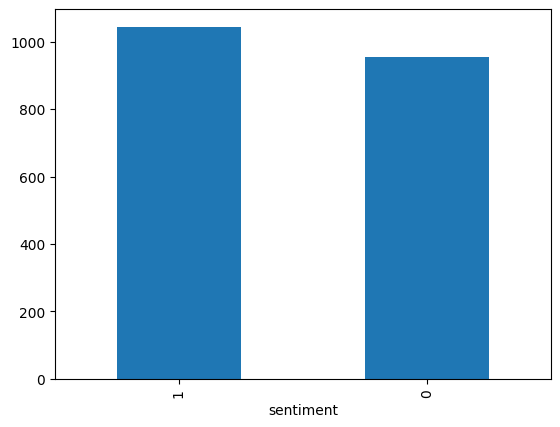

In [7]:
labeled_df['sentiment'].value_counts().plot(kind='bar')

Let's also see the review's length distribution using a histogram visualization.

<Axes: >

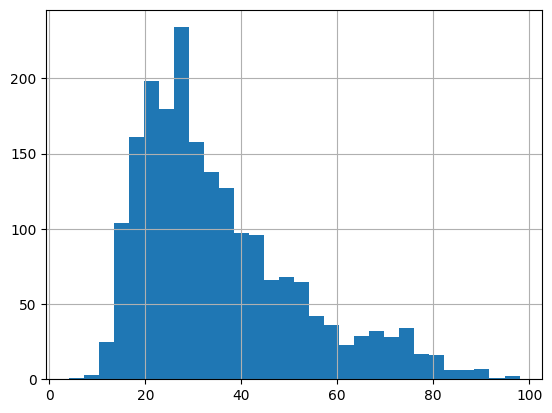

In [8]:
seq_len = [len(i.split()) for i in labeled_df['review'].tolist()]

pd.Series(seq_len).hist(bins = 30)

Now, let's create the function for text preprocessing.

In [9]:
def preprocessing(text):
  text = text.lower() # lowercase the text
  text = re.sub(r'https?://\S+|www\.\S+', '', text) # clean url
  text = re.sub(r'[@#]', '', text) # clean only @ and # symbol, preserving the user and hashtag text
  text = re.sub(r'[^a-zA-Z0-9 .,?!-]', ' ', text) # clean non-alphanumeric character, preserving basic punctuation mark

  # clean repeated basic punctuation marks, leaving only one punctuation mark
  text = re.sub(r'(\.)\1+', r'\1', text)
  text = re.sub(r'(\,)\1+', r'\1', text)
  text = re.sub(r'(\!)\1+', r'\1', text)
  text = re.sub(r'(\?)\1+', r'\1', text)

  text = re.sub(r'\s+', ' ', text).strip() # clean ectra spaces
  return text

Apply the function to the reviews in the labeled dataset.

In [10]:
labeled_df['review'] = labeled_df['review'].apply(preprocessing)

In [11]:
labeled_df

,ratings,review,sentiment
0,1,mengapa setiap saya mau klaim produk spesial p...,0
1,1,"maaf ya shopee, tapi aplikasinya sekarang mema...",0
2,2,"gk nampilin gambar saat cari barang, cuman nam...",0
3,3,aplikasi marketplace terlalu lebay. terlalu ba...,0
4,3,"permainan shopee tangkap, di android 10, koin ...",0
...,...,...,...
1995,5,"sangat sangat bermanfaat dan membantu, saat me...",1
1996,3,kak. pesanan udah di terima pembeli kenapa sal...,0
1997,5,"paling murmer pengirimannya, gk pernah mengece...",1
1998,2,kenapa akhir akhir ini shoppe saya gak ada gam...,0


#### Train-validation-Test Split

In [11]:
# separate input and label
input_data = labeled_df['review'].values
label_data = labeled_df['sentiment'].values.astype(np.float32)

In [21]:
input_data[:5]

array(['mengapa setiap saya mau klaim produk spesial pengguna baru selalu ada tulisan produk telah di klaim,silahkan klaim produk lain ?',
       'maaf ya shopee, tapi aplikasinya sekarang memang ampas sekali. sudah clear cache. sudah update versi paling baru. sudah uninstall install lagi. tetap saja lemotnyaaa bikin emosi. buang waktu. tolong benerin ya baru saya ubah bintangnya.',
       'gk nampilin gambar saat cari barang, cuman nampilin nama barangnya aja, gk tau ntah aplikasinya yg berat atau signal saya yg buruk padahal aplikasinya slalu saya update, tpi saya buka app olshop sebelah lancar aja padahal gk pernah saya update, tolong untuk developer nya dikembangkan lagi terutama untuk servernya mungkin berat diserver atau diaplikasinya yg terlalu banyak memakai animasi. u',
       'aplikasi marketplace terlalu lebay. terlalu banyak splash, cokie dan chace. jadinya platform terlemot di hp ane. kepada developer, jangan terlalu lebay lah bikin artworknya. malah lemot jadinya. simpel 

In [12]:
label_data[:5]

array([0., 0., 0., 0., 0.], dtype=float32)

Here, we split the labeled dataset into train, validation, and test set with ratio 80:10:10, respectively.

In [13]:
from sklearn.model_selection import train_test_split

input_train, input_valtest, label_train, label_valtest = train_test_split(input_data,
                                                                          label_data,
                                                                          test_size = 0.2,
                                                                          random_state = 42)
input_val, input_test, label_val, label_test = train_test_split(input_valtest,
                                                                label_valtest,
                                                                test_size = 0.5,
                                                                random_state = 42)

print(f'Input Train shape: {input_train.shape}')
print(f'Input Validation shape: {input_val.shape}')
print(f'Input Test shape: {input_test.shape}')
print(f'Label Train shape: {label_train.shape}')
print(f'Label Validation shape: {label_val.shape}')
print(f'Label Test shape: {label_test.shape}')

Input Train shape: (1600,)
Input Validation shape: (200,)
Input Test shape: (200,)
Label Train shape: (1600,)
Label Validation shape: (200,)
Label Test shape: (200,)


In [47]:
input_train[:5]

array(['tolong tanggung jawab ny dari pihak shopee sendiri, saya dari tanggal 19 nov sudah membayar tagihan, tetapi mengapa sampe skrg tgl 21 nov kok belum terbayar',
       'shopee jahat banget,aku top up shopeepay 2 kali lain bank,ngk masuk terus lapor udah kembali yg 400rb yg 800 belum udah 1 minggu lebih,trus aku ganti akun baru biar ngk terjadi lagi,ehh masih sama,saldo bank udah kepotong tolong dibantu ya ,padahal aku lagi butuh banget tapi saldo ngak masuk, pokoknya kalo saldonya belum balik aku ngk mau kasih bintang 5 lagi',
       'masak tiba koin dikurangi 10.560 ? kurangin sistem gimana sih ? aneh banget shopee. kan aku pake voucher kemaren. dpt koin 14rb. sekarang tiba dr shopee ngurangin.',
       'shopee feed nya bermasalah. cuma beberapa item yg bisa di feed .kalo di scroll ke bawah berulang barang2 yg di etalase paling atas saja.barang yg lain tidak bisa di jadikan feed',
       'aplikasi toko online terpercaya terlengkap dan banyak bonus ongkirnya, semoga terus maju da

In [49]:
label_train[:5]

tensor([1., 0., 0., 1., 1.])

#### Tokenize Input

In [14]:
def tokenize_input(input_data, tokenizer, max_length=128):
  tokenized_input = tokenizer(input_data.tolist(),
                              max_length = max_length,
                              padding = 'max_length',
                              truncation = True,
                              return_tensors = 'pt')
  return tokenized_input

In [15]:
token_train = tokenize_input(input_train, bert_tokenizer)
token_val = tokenize_input(input_val, bert_tokenizer)
token_test = tokenize_input(input_test, bert_tokenizer)

In [18]:
token_train

{'input_ids': tensor([[    2,  3854,  3353,  ...,     0,     0,     0],
        [    2,  6505,  2628,  ...,     0,     0,     0],
        [    2,  5968,  3598,  ...,     0,     0,     0],
        ...,
        [    2,    90,   305,  ...,     0,     0,     0],
        [    2, 21902,   963,  ...,     0,     0,     0],
        [    2, 15971,    26,  ...,     0,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]])}

In [21]:
token_train['input_ids']

tensor([[    2,  3854,  3353,  ...,     0,     0,     0],
        [    2,  6505,  2628,  ...,     0,     0,     0],
        [    2,  5968,  3598,  ...,     0,     0,     0],
        ...,
        [    2,    90,   305,  ...,     0,     0,     0],
        [    2, 21902,   963,  ...,     0,     0,     0],
        [    2, 15971,    26,  ...,     0,     0,     0]])

In [22]:
token_train['input_ids'].shape

torch.Size([1600, 128])

#### Convert The Labels to Tensor

In [32]:
label_train = torch.tensor(label_train, dtype=torch.float32)
label_val = torch.tensor(label_val, dtype=torch.float32)
label_test = torch.tensor(label_test, dtype=torch.float32)

In [46]:
label_train[:5]

tensor([1., 0., 0., 1., 1.])

#### Create The DataLoader

In [33]:
train_dataset = TensorDataset(token_train['input_ids'],
                              token_train['attention_mask'],
                              label_train)
val_dataset = TensorDataset(token_val['input_ids'],
                            token_val['attention_mask'],
                            label_val)
test_dataset = TensorDataset(token_test['input_ids'],
                             token_test['attention_mask'],
                             label_test)

In [34]:
train_dataloader = DataLoader(train_dataset,
                              batch_size = 32,
                              shuffle = True)
val_dataloader = DataLoader(val_dataset,
                            batch_size = 32,
                            shuffle = False)
test_dataloader = DataLoader(test_dataset,
                             batch_size = 32,
                             shuffle = False)

### BERT-NN Architecture

The sentiment analysis engine employs a BERT-NN (Neural Network) Transfer Learning approach under a frozen feature extraction setup to classify textual polarity (e.g., Positive vs. Negative).

Architectural Mechanics

1. Frozen Encoder Base: Rather than fine-tuning the entire 110M+ parameters of IndoBERT, all layers of the base Transformer ($\Theta_{\text{BERT}}$) are frozen ($\nabla_{\Theta_{\text{BERT}}} \mathcal{L} = 0$). This drastically reduces training latency while preserving deep contextual representations.

2. Classification Head: A custom single-neuron Fully Connected (FC) layer is appended directly to the classification representation:$$\mathbf{x}_{\text{CLS}} = \text{IndoBERT}(\mathbf{x})[\text{[CLS]}]$$

3. Forward Pass & Activation: The logit is projected via weight matrix $\mathbf{W} \in \mathbb{R}^{1 \times 768}$ and bias $b \in \mathbb{R}$, then mapped to a continuous probability space $[0, 1]$ via the Sigmoid function:$$\hat{y} = \sigma(\mathbf{W} \mathbf{x}_{\text{CLS}} + b) = \frac{1}{1 + e^{-(\mathbf{W} \mathbf{x}_{\text{CLS}} + b)}}$$

In [73]:
class BERTNN(nn.Module, PyTorchModelHubMixin):
  def __init__(self, bert_model):
    super().__init__()
    self.bert = bert_model

    # freeze all bert's parameters
    for param in self.bert.parameters():
      param.requires_grad = False

    # fully connected layer from bert's 768 sized pooled output/cls vector to 1 classifier neuron
    self.fc = nn.Linear(768, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, input_ids, attention_mask):
    bert_output = self.bert(input_ids, attention_mask)
    cls = bert_output.pooler_output
    fc_output = self.fc(cls)
    prob = self.sigmoid(fc_output)

    return prob

### Train BERT-NN

In [74]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Used device: {device}")

Used device: cuda


The trainable weights ($\mathbf{W}, b$) are optimized using Binary Cross-Entropy Loss (BCELoss) paired with AdamW ($\text{lr} = 10^{-3}, \text{weight\_decay} = 10^{-3}$ for $L_2$ regularization):$$\mathcal{L}_{\text{BCE}} = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

In [75]:
model = BERTNN(bert_model)
model.to(device)

# loss function: binary bross entropy loss since this is a binary classification problem
criterion = nn.BCELoss()

# optimizer: adamw with learning rate 10^-3 and regularizer/weight decay 10^-3
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()), # filter only fully connected parameters that will be trained
    lr=1e-3,
    weight_decay=1e-3
    )

In [76]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"Total Parameter: {total_params}")
print(f"Trainable Parameter: {trainable_params}")
print(f"Frozen Parameter: {total_params - trainable_params}") # frozen bert's parameters

Total Parameter: 124442113
Trainable Parameter: 769
Frozen Parameter: 124441344


Create training and validation loop

In [77]:
print('Training Model Started...')
epochs = 25
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(epochs):
  print(f"\n--- Epoch {epoch + 1}/{epochs} ---")
  # training mode
  model.train()
  train_losses = []
  train_correct = 0
  total_train_samples = 0
  for batch in train_dataloader:
    batch_input_ids = batch[0].to(device)
    batch_attention_mask = batch[1].to(device)
    batch_label = batch[2].to(device).unsqueeze(1) # reshape the labels to have 1 column

    # reset the gradien
    optimizer.zero_grad()

    # predict the probability
    probs = model(input_ids=batch_input_ids, attention_mask=batch_attention_mask)
    probs_clamped = torch.clamp(probs, min=1e-7, max=1.0 - 1e-7) # prevent log(0) in BCELoss

    # compute loss
    loss = criterion(probs_clamped, batch_label)

    # backward pass and update weights
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())
    preds = (probs >= 0.5).float()
    train_correct += (preds == batch_label).sum().item()
    total_train_samples += batch_label.size(0)

  epoch_train_loss = np.mean(train_losses)
  epoch_train_acc = train_correct / total_train_samples

  # evaluation mode
  model.eval()
  val_losses = []
  val_correct = 0
  total_val_samples = 0
  for batch in val_dataloader:
    batch_input_ids = batch[0].to(device)
    batch_attention_mask = batch[1].to(device)
    batch_label = batch[2].to(device).unsqueeze(1) # reshape the labels to have 1 column

    with torch.no_grad():
      # predict the probability
      probs = model(input_ids=batch_input_ids, attention_mask=batch_attention_mask)
      probs_clamped = torch.clamp(probs, min=1e-7, max=1.0 - 1e-7) # prevent log(0) in BCELoss

      # compute loss
      loss = criterion(probs_clamped, batch_label)

      val_losses.append(loss.item())
      preds = (probs >= 0.5).float()
      val_correct += (preds == batch_label).sum().item()
      total_val_samples += batch_label.size(0)

  epoch_val_loss = np.mean(val_losses)
  epoch_val_acc = val_correct / total_val_samples

  # save to the history
  history['train_loss'].append(epoch_train_loss)
  history['train_acc'].append(epoch_train_acc)
  history['val_loss'].append(epoch_val_loss)
  history['val_acc'].append(epoch_val_acc)

  print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")
  print(f"Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.4f}")

Training Model Started...

--- Epoch 1/25 ---
Train Loss: 0.6143 | Train Acc: 0.6750
Val Loss:   0.5502 | Val Acc:   0.7300

--- Epoch 2/25 ---
Train Loss: 0.5448 | Train Acc: 0.7438
Val Loss:   0.4861 | Val Acc:   0.7750

--- Epoch 3/25 ---
Train Loss: 0.5024 | Train Acc: 0.7769
Val Loss:   0.4860 | Val Acc:   0.7450

--- Epoch 4/25 ---
Train Loss: 0.4842 | Train Acc: 0.7800
Val Loss:   0.4586 | Val Acc:   0.7600

--- Epoch 5/25 ---
Train Loss: 0.4600 | Train Acc: 0.7919
Val Loss:   0.4347 | Val Acc:   0.7750

--- Epoch 6/25 ---
Train Loss: 0.4489 | Train Acc: 0.8031
Val Loss:   0.4435 | Val Acc:   0.7750

--- Epoch 7/25 ---
Train Loss: 0.4432 | Train Acc: 0.8094
Val Loss:   0.4147 | Val Acc:   0.7900

--- Epoch 8/25 ---
Train Loss: 0.4292 | Train Acc: 0.8094
Val Loss:   0.4085 | Val Acc:   0.7700

--- Epoch 9/25 ---
Train Loss: 0.4210 | Train Acc: 0.8163
Val Loss:   0.4045 | Val Acc:   0.7950

--- Epoch 10/25 ---
Train Loss: 0.4162 | Train Acc: 0.8181
Val Loss:   0.4251 | Val Acc:   

### BERT-NN Evaluation

In [78]:
history_df = pd.DataFrame(history)
history_df.to_csv('data/history.csv', index=False)

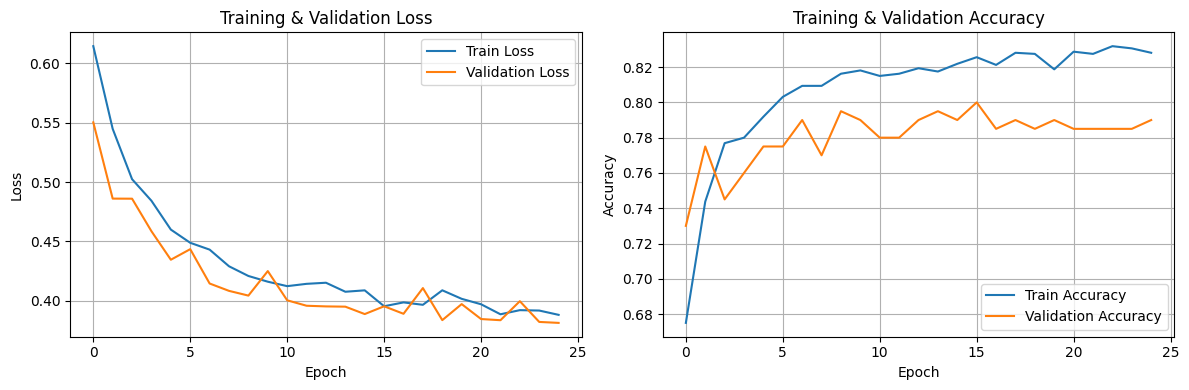

In [79]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# plot loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Validation Accuracy')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [80]:
# predict the data test
model.eval()
test_preds = []
test_labels = []
with torch.no_grad():
  for batch in test_dataloader:
    batch_input_ids = batch[0].to(device)
    batch_attention_mask = batch[1].to(device)
    batch_label = batch[2].to(device).unsqueeze(1) # reshape the labels to have 1 column

    probs = model(input_ids=batch_input_ids, attention_mask=batch_attention_mask)
    preds = (probs >= 0.5).float()

    test_preds.extend(preds.cpu().numpy())
    test_labels.extend(batch_label.cpu().numpy())

test_preds = np.array(test_preds)
test_labels = np.array(test_labels)

In [81]:
test_preds = test_preds.reshape(-1)
test_labels = test_labels.reshape(-1)

In [82]:
test_preds

array([0., 1., 0., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 0., 1.,
       1., 0., 1., 1., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0., 0., 0., 0.,
       0., 0., 1., 1., 1., 0., 0., 0., 1., 0., 0., 1., 0., 0., 1., 1., 0.,
       0., 1., 0., 1., 1., 1., 0., 0., 0., 1., 0., 1., 0., 0., 1., 1., 0.,
       0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0.,
       0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 1., 1., 0., 0., 1.,
       1., 0., 0., 1., 0., 1., 0., 1., 1., 0., 0., 1., 1., 1., 0., 0., 1.,
       1., 1., 0., 1., 0., 0., 1., 0., 0., 0., 0., 1., 0., 1., 0., 0., 1.,
       1., 1., 0., 0., 0., 1., 0., 1., 1., 1., 1., 1., 0., 0., 1., 0., 1.,
       0., 0., 1., 1., 1., 0., 1., 0., 0., 1., 1., 1., 0., 0., 0., 1., 0.,
       0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 1., 1., 1., 1., 1., 1., 0.,
       0., 0., 0., 1., 1., 0., 1., 0., 0., 0., 0., 1., 1.], dtype=float32)

In [83]:
test_labels

array([0., 1., 1., 1., 0., 1., 1., 0., 0., 0., 1., 1., 1., 1., 1., 0., 1.,
       0., 0., 1., 1., 0., 1., 0., 1., 0., 0., 1., 1., 1., 0., 1., 0., 0.,
       0., 0., 1., 1., 1., 0., 0., 0., 1., 1., 0., 1., 0., 0., 1., 1., 1.,
       0., 1., 0., 0., 1., 1., 0., 1., 0., 1., 0., 1., 0., 0., 1., 1., 0.,
       0., 0., 1., 0., 0., 1., 1., 1., 1., 1., 1., 0., 0., 0., 1., 0., 0.,
       0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0., 1., 1., 1., 0., 1.,
       1., 0., 0., 0., 0., 1., 1., 1., 1., 0., 0., 1., 1., 1., 0., 1., 1.,
       1., 1., 1., 1., 0., 0., 1., 1., 0., 0., 0., 1., 0., 1., 0., 0., 1.,
       0., 1., 0., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 1., 0., 1.,
       0., 0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 1., 0., 0., 0., 1., 0.,
       0., 0., 0., 0., 0., 1., 0., 1., 0., 1., 1., 1., 1., 1., 0., 1., 0.,
       0., 0., 0., 1., 1., 1., 1., 0., 0., 0., 0., 0., 1.], dtype=float32)

--- Classification Report ---
Classification Report:

              precision    recall  f1-score   support

         0.0       0.81      0.88      0.85       102
         1.0       0.87      0.79      0.82        98

    accuracy                           0.83       200
   macro avg       0.84      0.83      0.83       200
weighted avg       0.84      0.83      0.83       200

--- Confusion Matrix ---


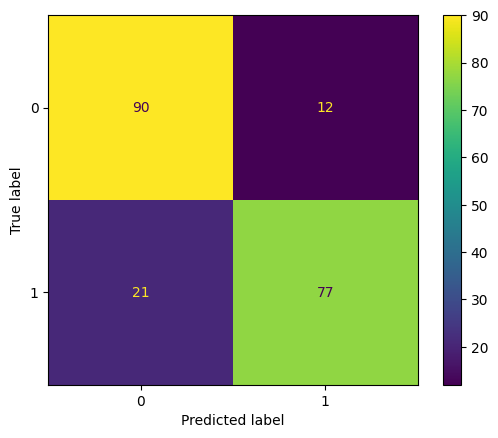

In [84]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("--- Classification Report ---")
report = classification_report(test_labels, test_preds)
print('Classification Report:\n')
print(report)

print("--- Confusion Matrix ---")
cm = confusion_matrix(test_labels, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

### Save Model to HuggingFace

In [85]:
hf_token = userdata.get('HF_TOKEN')

login(token=hf_token)

In [86]:
repo_id = 'RubikRif/bertnn-shopee-sentiment-analysis'

model.push_to_hub(repo_id,
                  commit_message='feat: indobert transfer learning model result (epoch 25, acc 0.83)')

bert_tokenizer.push_to_hub(repo_id,
                           commit_message='add: tokenizer')

README.md:   0%|          | 0.00/352 [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/RubikRif/bertnn-shopee-sentiment-analysis/commit/fd3e59616e457a641ec9d3f5da25a6e560060534', commit_message='add: tokenizer', commit_description='', oid='fd3e59616e457a641ec9d3f5da25a6e560060534', pr_url=None, repo_url=RepoUrl('https://huggingface.co/RubikRif/bertnn-shopee-sentiment-analysis', endpoint='https://huggingface.co', repo_type='model', repo_id='RubikRif/bertnn-shopee-sentiment-analysis'), pr_revision=None, pr_num=None)

### Use The Model to Predict Unlabeled Dataset

In [87]:
unlabeled_df = pd.read_excel('data/shopee_unlabeled_data.xlsx')
unlabeled_df

,ratings,review
0,3,Di shopee sekarang gratis ongkir hanya terten...
1,1,"Sungguh tidak membantu ,udah pesen nya ga bil..."
2,5,Sangat membantu saya dalam hal berbelanja dan...
3,4,Aku kok ga bisa pake shopee paylater ya?? Pad...
4,5,"Belanja di shopee responsif, aman, nyaman, te..."
...,...,...
4992,1,Makin kesini kenapa Sekarang shopee sering ngl...
4993,1,"Lemottttttt. Hp kenceng, wifi kenceng. Shopee?..."
4994,5,Sangat nyaman belanja di Shopee..karena ongkir...
4995,2,"Dah lama gak pakai shopee, coba install lg.. S..."


In [88]:
unlabeled_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   ratings  4997 non-null   int64 
 1   review   4997 non-null   object
dtypes: int64(1), object(1)
memory usage: 78.2+ KB


In [89]:
unlabeled_df['review'] = unlabeled_df['review'].apply(preprocessing)

In [91]:
input_unlabeled = unlabeled_df['review'].values
token_unlabeled = tokenize_input(input_unlabeled, bert_tokenizer)

In [92]:
token_unlabeled

{'input_ids': tensor([[   2,   26, 6505,  ...,    0,    0,    0],
        [   2, 3566,  119,  ...,    0,    0,    0],
        [   2,  310, 1055,  ...,    0,    0,    0],
        ...,
        [   2,  310, 2382,  ...,    0,    0,    0],
        [   2, 1299,  985,  ...,    0,    0,    0],
        [   2, 6379, 2983,  ...,    0,    0,    0]]), 'token_type_ids': tensor([[0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]])}

In [93]:
unlabeled_dataset = TensorDataset(
    token_unlabeled['input_ids'],
    token_unlabeled['attention_mask']
)

unlabeled_dataloader = DataLoader(
    unlabeled_dataset,
    batch_size=32,
    shuffle=False
)

In [94]:
# predict the unlabeled data
model.eval()
unlabeled_preds = []
with torch.no_grad():
  for batch in unlabeled_dataloader:
    batch_input_ids = batch[0].to(device)
    batch_attention_mask = batch[1].to(device)

    probs = model(input_ids=batch_input_ids, attention_mask=batch_attention_mask)
    preds = (probs >= 0.5).float()

    unlabeled_preds.extend(preds.cpu().numpy())

unlabeled_preds = np.array(unlabeled_preds).reshape(-1)

In [95]:
unlabeled_preds

array([0., 0., 1., ..., 1., 0., 0.], dtype=float32)

In [96]:
unlabeled_preds = unlabeled_preds.astype(int)

In [97]:
unlabeled_preds

array([0, 0, 1, ..., 1, 0, 0])

In [98]:
unlabeled_df['sentiment'] = unlabeled_preds

In [99]:
unlabeled_df

,ratings,review,sentiment
0,3,di shopee sekarang gratis ongkir hanya tertent...,0
1,1,"sungguh tidak membantu ,udah pesen nya ga bila...",0
2,5,sangat membantu saya dalam hal berbelanja dan ...,1
3,4,aku kok ga bisa pake shopee paylater ya? padah...,0
4,5,"belanja di shopee responsif, aman, nyaman, ter...",1
...,...,...,...
4992,1,makin kesini kenapa sekarang shopee sering ngl...,0
4993,1,"lemottttttt. hp kenceng, wifi kenceng. shopee?...",0
4994,5,sangat nyaman belanja di shopee.karena ongkir ...,1
4995,2,"dah lama gak pakai shopee, coba install lg. se...",0


### Concatenate The Labeled Dataset with Predicted Sentiment Dataset and Save Results

In [100]:
result = pd.concat([labeled_df, unlabeled_df], ignore_index=True)
result

,ratings,review,sentiment
0,1,mengapa setiap saya mau klaim produk spesial p...,0
1,1,"maaf ya shopee, tapi aplikasinya sekarang mema...",0
2,2,"gk nampilin gambar saat cari barang, cuman nam...",0
3,3,aplikasi marketplace terlalu lebay. terlalu ba...,0
4,3,"permainan shopee tangkap, di android 10, koin ...",0
...,...,...,...
6992,1,makin kesini kenapa sekarang shopee sering ngl...,0
6993,1,"lemottttttt. hp kenceng, wifi kenceng. shopee?...",0
6994,5,sangat nyaman belanja di shopee.karena ongkir ...,1
6995,2,"dah lama gak pakai shopee, coba install lg. se...",0


In [101]:
result.to_csv('data/shopee_sentiment_analysis_result.csv', index=False)

### Visualize Results

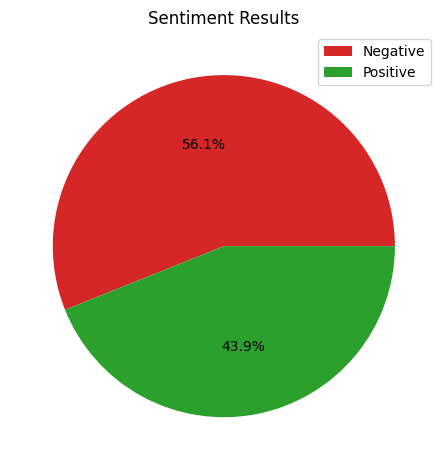

In [103]:
x = [result['sentiment'].value_counts()[0], result['sentiment'].value_counts()[1]]
details = ['Negative', 'Positive']
colors = ['tab:red', 'tab:green']

fig, ax = plt.subplots()
ax.pie(x, colors=colors, autopct='%.1f%%')
ax.set_title('Sentiment Results')
plt.legend(details)
plt.tight_layout()

## Topic Detection with BERT-EFCM

To discover latent topics without human supervision, the system uses a BERT-EFCM (Eigen-based Fuzzy C-Means).

Step 1: Contextual Mean-Pooling Embeddings

Unlike classification (which relies solely on the [CLS] token), topic discovery benefits from capturing semantic information across the entire sequence. We extract the full last_hidden_state $\mathbf{H} \in \mathbb{R}^{N \times L \times 768}$ (where $L$ is sequence length) and apply Attention-Masked Mean Pooling:$$\mathbf{e}_i = \frac{\sum_{j=1}^{L} \mathbf{H}_{i, j} \cdot m_{i, j}}{\sum_{j=1}^{L} m_{i, j}} \in \mathbb{R}^{768}$$where $m_{i, j} \in \{0, 1\}$ is the attention mask corresponding to token $j$ in document $i$.

Step 2: Eigen-Based Dimension Reduction (Truncated SVD)

High-dimensional dense embeddings ($d=768$) suffer from the curse of dimensionality during distance-based clustering. We apply Truncated Singular Value Decomposition (TSVD) to factorize the mean-pooled embedding matrix $\mathbf{E} \in \mathbb{R}^{N \times 768}$ into its principal eigen-subspace:$$\mathbf{E} \approx \mathbf{U}_k \mathbf{\Sigma}_k \mathbf{V}_k^T$$The reduced representation $\mathbf{Z} = \mathbf{E} \mathbf{V}_k \in \mathbb{R}^{N \times k}$ ($k \ll 768$) retains maximum data variance along orthogonal eigenvectors while removing isotropic noise.

Step 3: Fuzzy C-Means (FCM) Soft Clustering

Instead of hard boundary assignments (like $k$-Means), Fuzzy C-Means allows each document $i$ to hold degree of membership $u_{ij} \in [0, 1]$ across $C$ topic cluster centers $\mathbf{v}_j$:$$\min_{\mathbf{U}, \mathbf{V}} J_m = \sum_{i=1}^{N} \sum_{j=1}^{C} u_{ij}^m \Vert{}\mathbf{z}_i - \mathbf{v}_j\Vert{}^2$$ $$\text{subject to} \quad \sum_{j=1}^{C} u_{ij} = 1, \quad \forall i$$where $m > 1$ is the fuzziness exponent. This soft assignment naturally models real-world documents that span multiple latent topics simultaneously.

### Data Preprocessing for Topic Detection

In [106]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords', quiet=True)

True

In [107]:
stopwords_set = set(stopwords.words('indonesian'))

additional_stopwords = {
    'saya', 'sy', 'tp', 'tpi', 'gak', 'ga', 'gk', 'g',
    'nya', 'saat', 'sih', 'deh', 'dll', 'nih', 'donk',
    'min', 'ny', 'yg', 'si', 'eh', 'tu', 'mah', 'loh',
    'aja', 'udah', 'udh', 'ya', 'kalo', 'klo', 'dah',
    'cuman', 'aj', 'lg', 'lgi', 'tau', 'dh', 'cm', 'ajh'
}

# Gabungkan set
stopwords_set.update(additional_stopwords)

def preprocessing_topic(text):
  # clean all punctuation mark and non-alphanumeric characters
  text = re.sub(r'[^\w\s]', ' ', text)

  # clean numbers
  text = re.sub(r'\d+', ' ', text)

  # filter stopword + delete word with length <= 1 character
  words = text.split()
  clean_words = [word for word in words if word not in stopwords_set and len(word) > 1]

  return ' '.join(clean_words)

In [108]:
result

,ratings,review,sentiment
0,1,mengapa setiap saya mau klaim produk spesial p...,0
1,1,"maaf ya shopee, tapi aplikasinya sekarang mema...",0
2,2,"gk nampilin gambar saat cari barang, cuman nam...",0
3,3,aplikasi marketplace terlalu lebay. terlalu ba...,0
4,3,"permainan shopee tangkap, di android 10, koin ...",0
...,...,...,...
6992,1,makin kesini kenapa sekarang shopee sering ngl...,0
6993,1,"lemottttttt. hp kenceng, wifi kenceng. shopee?...",0
6994,5,sangat nyaman belanja di shopee.karena ongkir ...,1
6995,2,"dah lama gak pakai shopee, coba install lg. se...",0


In [109]:
result['review'] = result['review'].apply(preprocessing_topic)
result

,ratings,review,sentiment
0,1,klaim produk spesial pengguna tulisan produk k...,0
1,1,maaf shopee aplikasinya ampas clear cache upda...,0
2,2,nampilin gambar cari barang nampilin nama bara...,0
3,3,aplikasi marketplace lebay splash cokie chace ...,0
4,3,permainan shopee tangkap android koin turunnya...,0
...,...,...,...
6992,1,kesini shopee nglag susah log in gambar putih ...,0
6993,1,lemottttttt hp kenceng wifi kenceng shopee lem...,0
6994,5,nyaman belanja shopee ongkir gratisnya belanja...,1
6995,2,pakai shopee coba install login cari barang la...,0


### Define Utility Functions for BERT-EFCM

In [121]:
# get bert embedding function
def bert_embedding(data, bert_tokenizer, bert_model, batch_size=32, max_length=128, pooling_method='mean'):
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
  bert_model.to(device)
  bert_model.eval()

  all_embeddings = []

  # batch looping
  for i in range(0, len(data), batch_size):
    batch_text = list(data[i : i + batch_size])

    # batch tokenization
    inputs = bert_tokenizer(
      batch_text,
      max_length=max_length,
      padding='max_length',
      truncation=True,
      return_tensors='pt'
    )

    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)

    with torch.no_grad():
      outputs = bert_model(input_ids=input_ids, attention_mask=attention_mask)

      if pooling_method == 'cls':
        embeddings = outputs.pooler_output # shape: (batch_size, 768)

      elif pooling_method == 'mean':
        token_embeddings = outputs.last_hidden_state # shape: (batch_size, 128, 768)
        # expand attention_mask shape to (batch_size, 128, 768) too
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

        sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, 1)
        sum_mask = torch.clamp(input_mask_expanded.sum(1), min=1e-9) # count how many real token (not padding)
        embeddings = sum_embeddings / sum_mask

    all_embeddings.append(embeddings.cpu().numpy())

  return np.vstack(all_embeddings)

In [122]:
from sklearn.feature_extraction.text import CountVectorizer
# functions for topic interpretation

# c-TFIDF function
def c_tf_idf(documents, m, ngram_range=(1, 1)):
    count = CountVectorizer(ngram_range=ngram_range).fit(documents)
    t = count.transform(documents).toarray()
    w = t.sum(axis=1)
    tf = np.divide(t.T, w)
    sum_t = t.sum(axis=0)
    idf = np.log(np.divide(m, sum_t)).reshape(-1, 1)
    tf_idf = np.multiply(tf, idf)

    return tf_idf, count

# function for getting top words of a topic
def extract_top_words_per_topic(tf_idf, count, docs_per_topic, n = 10):
    words = count.get_feature_names_out()
    labels = list(docs_per_topic.Topic)
    tf_idf_transposed = tf_idf.T
    indices = tf_idf_transposed.argsort()[:, -n:]
    top_n_words = {label: [(words[j], tf_idf_transposed[i][j]) for j in indices[i]][::-1] for i, label in enumerate(labels)}
    top_words = []
    for i in range(len(labels)):
      top_words.append([words[j] for j in indices [i]][::-1])
    return top_words

#### Download Word2Vec Indonesia Model.

In [125]:
path = kagglehub.dataset_download("bhimantoros/pretrained-word2vec-indonesia")

print("Path:", path)

100%|██████████| 2.97G/2.97G [02:30<00:00, 21.2MB/s]

Extracting files...


Path: /root/.cache/kagglehub/datasets/bhimantoros/pretrained-word2vec-indonesia/versions/1


In [130]:
# get the main word2vec model
w2v_model_file = os.path.join(path, "wiki.id.case.model")

w2v_model = gensim.models.Word2Vec.load(w2v_model_file)

In [131]:
# function for computing coherence value
def calculate_coherence(w2v_model, term_rankings):
    overall_coherence = 0.0
    for topic_index in range(len(term_rankings)):
        # check each pair of terms
        pair_scores = []
        for i in range(len(term_rankings[topic_index])):
            for j in range(i + 1, len(term_rankings[topic_index])):
                term_i = term_rankings[topic_index][i]
                term_j = term_rankings[topic_index][j]
                if term_i in w2v_model.wv.key_to_index and term_j in w2v_model.wv.key_to_index:
                    pair_scores.append(w2v_model.wv.similarity(term_i, term_j))

        # get the mean for all pairs in this topic
        if pair_scores:
            topic_score = sum(pair_scores) / len(pair_scores)
            overall_coherence += topic_score

    # get the mean score across all topics
    return overall_coherence / len(term_rankings)

### Topic Detection Simulation using BERT-EFCM

First, get the BERT embeddings.

In [133]:
embeddings = bert_embedding(
    data=result['review'].tolist(),
    bert_tokenizer=bert_tokenizer,
    bert_model=bert_model,
    batch_size=32,
    pooling_method='mean' # Gunakan 'cls' kalau mau persis output TF [1] lu dulu
)

Then, use the Truncated Singular Value Decomposition (Eigen-Based) to reduce the embeddings vector size.

In [134]:
from sklearn.decomposition import TruncatedSVD

# efcm
svd = TruncatedSVD(n_components = 5)
data = svd.fit_transform(embeddings)

Run the topic detection simulation using Fuzzy C-Means clustering.

In [137]:
# use fuzzy c-means clustering to get topic clusters
import skfuzzy as fuzzy

# seaching the best N topics
num_topics = []
coherences = []

for n_topics in range(1, 21):  # try values from 1 to 20
    print("The number of topics is " + str(n_topics))

    coherence_sim = []
    for i in range(1, 4):  # perform simulations
        print("> Simulation " + str(i))

        # Topic detection
        m = 1.1
        cntr, u, u0, d, jm, p, fpc = fuzzy.cluster.cmeans(data.T, n_topics, m, error=0.0001, maxiter=200, init=None)
        cluster_membership = np.argmax(u, axis=0)

        docs = pd.DataFrame(list(result["review"]), columns=["Doc"])
        docs['Topic'] = cluster_membership
        docs['Doc_ID'] = range(len(docs))
        docs_per_topic = docs.dropna(subset=['Doc']).groupby(['Topic'], as_index=False).agg({'Doc': ' '.join})

        tf_idf, count = c_tf_idf(docs_per_topic.Doc.values, m=len(docs))
        top_words = extract_top_words_per_topic(tf_idf, count, docs_per_topic, 10)

        coherence_sim.append(calculate_coherence(w2v_model, top_words))
        print('Coherence value:', coherence_sim[i-1])

    num_topics.append(n_topics)
    coherences.append(coherence_sim)
    print(50*'=')

best_num_topics = num_topics[np.argmax(np.mean(coherences, axis=1))]
best_coherence = np.max(np.mean(coherences, axis=1))

print("Best number of topics:", best_num_topics)
print("Best coherence:", best_coherence)

The number of topics is 1
> Simulation 1
Coherence value: 0.17422128
> Simulation 2
Coherence value: 0.17422128
> Simulation 3
Coherence value: 0.17422128
The number of topics is 2
> Simulation 1
Coherence value: 0.23230776
> Simulation 2
Coherence value: 0.23230776
> Simulation 3
Coherence value: 0.23230776
The number of topics is 3
> Simulation 1
Coherence value: 0.18822284
> Simulation 2
Coherence value: 0.18822283
> Simulation 3
Coherence value: 0.18822284
The number of topics is 4
> Simulation 1
Coherence value: 0.2270459
> Simulation 2
Coherence value: 0.2270459
> Simulation 3
Coherence value: 0.22704588
The number of topics is 5
> Simulation 1
Coherence value: 0.20064195
> Simulation 2
Coherence value: 0.20064195
> Simulation 3
Coherence value: 0.20064195
The number of topics is 6
> Simulation 1
Coherence value: 0.22579135
> Simulation 2
Coherence value: 0.20217156
> Simulation 3
Coherence value: 0.20217156
The number of topics is 7
> Simulation 1
Coherence value: 0.19273593
> S

Here, we get the **best number of topics = 2**.

Plot the results.

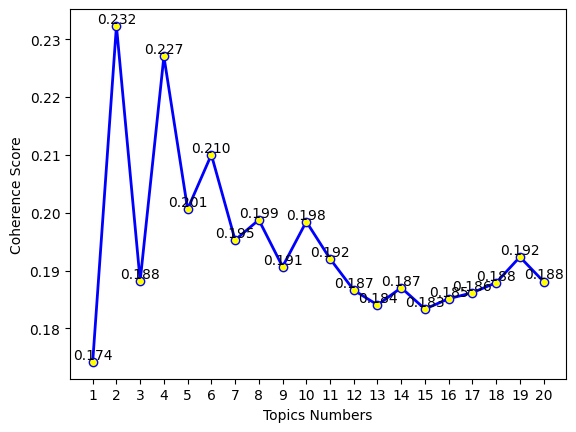

In [138]:
# compute the coherence score
coherence_avg = [np.mean(sim) for sim in coherences]

# create line plot
plt.plot(num_topics, coherence_avg, color='b', marker='o',
         markerfacecolor='yellow', linewidth=2)
plt.xlabel('Topics Numbers')
plt.ylabel('Coherence Score')

plt.xticks(np.arange(min(num_topics), max(num_topics)+1, 1))

for i, coherence in enumerate(coherence_avg):
    plt.text(num_topics[i], coherence, f'{coherence:.3f}', ha='center',
             va='bottom')

plt.show()

Get topics using the Best N Topic.

In [140]:
m = 1.1
n_topics = best_num_topics # best number of topics
cntr, u, u0, d, jm, p, fpc = fuzzy.cluster.cmeans(data.T, n_topics, m, error=0.0001, maxiter=200, init=None)
cluster_membership = np.argmax(u, axis=0)

# Representasi topik
docs = pd.DataFrame(list(result["review"]), columns=["Doc"])
docs['Topic'] = cluster_membership
docs['Doc_ID'] = range(len(docs))
docs_per_topic = docs.dropna(subset=['Doc']).groupby(['Topic'], as_index = False).agg({'Doc': ' '.join})

tf_idf, count = c_tf_idf(docs_per_topic.Doc.values, m=len(docs))
top_words = extract_top_words_per_topic(tf_idf, count, docs_per_topic, 10)

In [141]:
docs

,Doc,Topic,Doc_ID
0,klaim produk spesial pengguna tulisan produk k...,0,0
1,maaf shopee aplikasinya ampas clear cache upda...,1,1
2,nampilin gambar cari barang nampilin nama bara...,1,2
3,aplikasi marketplace lebay splash cokie chace ...,1,3
4,permainan shopee tangkap android koin turunnya...,1,4
...,...,...,...
6992,kesini shopee nglag susah log in gambar putih ...,1,6992
6993,lemottttttt hp kenceng wifi kenceng shopee lem...,1,6993
6994,nyaman belanja shopee ongkir gratisnya belanja...,0,6994
6995,pakai shopee coba install login cari barang la...,1,6995


### Topic Detection Results

In [142]:
from tabulate import tabulate

table = []
i = 1
for wordlist in top_words:
  templist = []
  templist.append('Topic ' + str(i))
  templist.append(', '.join(wordlist))
  table.append(templist)
  i += 1

print(tabulate(table, tablefmt = 'fancy_grid'))

╒═════════╤══════════════════════════════════════════════════════════════════════════════════╕
│ Topic 1 │ ongkir, belanja, gratis, barang, voucher, penjual, pay, harga, pengiriman, beli  │
├─────────┼──────────────────────────────────────────────────────────────────────────────────┤
│ Topic 2 │ lemot, aplikasi, buka, update, tolong, jaringan, banget, hp, aplikasinya, lancar │
╘═════════╧══════════════════════════════════════════════════════════════════════════════════╛


### Topic Interpretation & Analysis

**Topic 1: E-Commerce Transactions, Promotions, & Logistics**

* Keywords: ongkir (shipping fee), belanja (shopping), gratis (free), barang (items), voucher, penjual (seller), pay, harga (price), pengiriman (delivery), beli (buy)

* Interpretation: This cluster captures user feedback regarding the business, promotional, and transactional aspects of the service. Discussions primarily revolve around cost-saving incentives (free shipping vouchers, discounts), payment integrations (e-wallet/pay), seller interactions, and order fulfillment/delivery performance.

**Topic 2: Technical Application Performance & User Experience**

* Keywords: lemot (laggy/slow), aplikasi (application), buka (open), update, tolong (help), jaringan (network), banget (very), hp (mobile phone), aplikasinya (the app), lancar (smooth)

* Interpretation: This cluster isolates discussions concerning system stability and software performance. Users express technical friction (app lag, crashes when opening, post-update bugs, device compatibility, and connectivity issues), along with contrasting positive feedback regarding app responsiveness (lancar).

In [143]:
result.head()

,ratings,review,sentiment
0,1,klaim produk spesial pengguna tulisan produk k...,0
1,1,maaf shopee aplikasinya ampas clear cache upda...,0
2,2,nampilin gambar cari barang nampilin nama bara...,0
3,3,aplikasi marketplace lebay splash cokie chace ...,0
4,3,permainan shopee tangkap android koin turunnya...,0


In [145]:
docs.head()

,Doc,Topic,Doc_ID
0,klaim produk spesial pengguna tulisan produk k...,0,0
1,maaf shopee aplikasinya ampas clear cache upda...,1,1
2,nampilin gambar cari barang nampilin nama bara...,1,2
3,aplikasi marketplace lebay splash cokie chace ...,1,3
4,permainan shopee tangkap android koin turunnya...,1,4


### Save The Topic Detection Results

In [147]:
result['topic'] = docs['Topic']

In [148]:
result

,ratings,review,sentiment,topic
0,1,klaim produk spesial pengguna tulisan produk k...,0,0
1,1,maaf shopee aplikasinya ampas clear cache upda...,0,1
2,2,nampilin gambar cari barang nampilin nama bara...,0,1
3,3,aplikasi marketplace lebay splash cokie chace ...,0,1
4,3,permainan shopee tangkap android koin turunnya...,0,1
...,...,...,...,...
6992,1,kesini shopee nglag susah log in gambar putih ...,0,1
6993,1,lemottttttt hp kenceng wifi kenceng shopee lem...,0,1
6994,5,nyaman belanja shopee ongkir gratisnya belanja...,1,0
6995,2,pakai shopee coba install login cari barang la...,0,1


In [149]:
result.to_csv('data/shopee_topic_level_sentiment_analysis_result.csv', index=False)

## Topic-Level Sentiment Analysis

In [150]:
topic_group = result.groupby('topic')

### Total Reviews for Each Topic

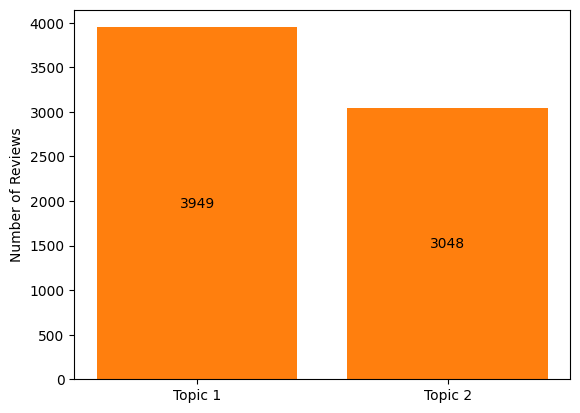

In [151]:
# visualize how many reviews for each topic
x = []
for i in range(n_topics):
  x.append('Topic ' + str(i + 1))

y = []
for i in range(n_topics):
  y.append(len(topic_group.get_group(i)))

plt.bar(x, y, color='tab:orange')
plt.ylabel("Number of Reviews")

for xpos, ypos, yval in zip(x, np.array(y)/2, y):
  plt.text(xpos, ypos, yval, ha="center", va="center")

plt.show()

### Sentiment for Each Topic

In [152]:
topic_group['sentiment'].value_counts()

topic  sentiment
0      1            2506
       0            1443
1      0            2480
       1             568
Name: count, dtype: int64

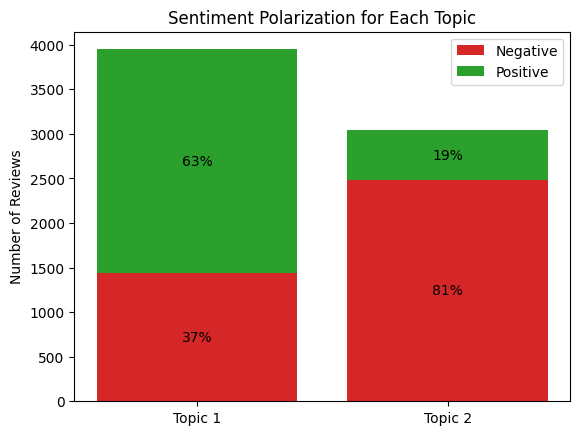

In [153]:
# visualize result
x = []
for i in range(n_topics):
  x.append('Topic ' + str(i + 1))

y1 = [] # negative
y2 = [] # positive
for i in range(n_topics):
  y1.append(topic_group['sentiment'].value_counts()[i][0])
  y2.append(topic_group['sentiment'].value_counts()[i][1])
y1 = np.array(y1)
y2 = np.array(y2)

keterangan = ['Negative', 'Positive']

plt.bar(x, y1, color='tab:red')
plt.bar(x, y2, bottom=y1, color='tab:green')
plt.ylabel("Number of Reviews")
plt.legend(keterangan)
plt.title('Sentiment Polarization for Each Topic')

# tambahkan persentase
percentage1 = (y1/(y1+y2)*100).round().astype(int)
percentage1 = list(percentage1)
for i in range(len(percentage1)):
  percentage1[i] = str(percentage1[i])+'%'
for xpos, ypos, yval in zip(x, y1/2, percentage1):
  plt.text(xpos, ypos, yval, ha="center", va="center")

percentage2 = (y2/(y1+y2)*100).round().astype(int)
percentage2 = list(percentage2)
for i in range(len(percentage2)):
  percentage2[i] = str(percentage2[i])+'%'
for xpos, ypos, yval in zip(x, y1+y2/2, percentage2):
  plt.text(xpos, ypos, yval, ha="center", va="center")

plt.show()

By integrating the predictions from the BERT-NN classifier with the thematic clusters generated by BERT-EFCM, we observe a clear polarization contrast between operational/promotional user experience (Topic 1) and technical application performance (Topic 2).

## Key Takeaways & Strategic Recommendations

|Aspect|Topic 1 (Promotions & Logistics)|Topic 2 (Technical Performance)|
|---|---|---|
|Dominant Sentiment|Positive (63%)|Negative (81%)|
|Primary Driver|Free shipping, discounts, payment UX|App slowness, crashes, update bugs|
|Business Priority|Maintain marketing incentives & improve seller SLA|Urgent Fix Needed: Software optimization & bug fixes|